# NYC Airbnb: Data Audit and Exploratory Analysis

Our goal is to predict a listing's advertised nightly price.

This notebook will:
* Inspect the dataset's struture and variables
* Check missing values, duplicates, and data quality
* Examine the price variable
* Explore relationships between listing characteristics and price

## Initial Data Exploration

In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

In [11]:
data_path = Path("../data/raw/listings.csv")

raw_listings = pd.read_csv(data_path, low_memory=False)
df = raw_listings.copy()

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

display(df.head())

Rows: 29,918
Columns: 90


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1352055619826961511,https://www.airbnb.com/rooms/1352055619826961511,20260914002229,2026-09-14,NaN,"New 3 bed, 1.5 bath",This stylish place to stay is perfect for group trips.,NaN,https://a0.muscache.com/pictures/miso/Hosting-1352055619826961511/original/22e6f279-de69-4833-b0...,677651543,https://www.airbnb.com/users/show/677651543,1470695597007476976,https://www.airbnb.com/users/profile/1470695597007476976,Shamar,NaN,1.0,7.0,0.0,3.0,NaN,NaN,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/Portrait/Avatars/v2/blue?im_w=240&im_t=S&im_s=86&im_f=AirbnbCerealLat...,NaN,1,NaN,NaN,f,t,NaN,East Flatbush,Brooklyn,40.640673,-73.928452,Entire rental unit,Entire home/apt,4,NaN,1.5 baths,3.0,3.0,"[""Kitchen"", ""Fire extinguisher"", ""Free parking on premises"", ""Air conditioning"", ""Smoke alarm""]",NaN,2026-09-14,2026-10-14,NaN,NaN,"{""quote"": {""taxes"": null, ""currency"": null, ""date_match"": null, ""service_fee"": null, ""total_pric...",30.0,365.0,30.0,30.0,365.0,365.0,30.0,365.0,NaN,NaN,30,60,90,365,2026-09-14,0,0,0,109,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,1215930899551057941,https://www.airbnb.com/rooms/1215930899551057941,20260914002229,2026-09-14,NaN,Queens apartament,Bring the whole family to this great place with lots of room for fun.,NaN,https://a0.muscache.com/pictures/hosting/Hosting-1215930899551057941/original/27ec00c7-86e8-4475...,392517036,https://www.airbnb.com/users/show/392517036,1469814056304456331,https://www.airbnb.com/users/profile/1469814056304456331,Roman,NaN,5.0,6.0,2.0,0.0,NaN,NaN,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/Portrait/Avatars/v2/orange?im_w=240&im_t=R&im_s=86&im_f=AirbnbCerealL...,NaN,1,NaN,NaN,f,t,NaN,Maspeth,Queens,40.721708,-73.907840,Private room in rental unit,Private room,5,NaN,1 private bath,2.0,1.0,"[""TV"", ""Kitchen"", ""Fire extinguisher"", ""Air conditioning"", ""Dedicated workspace"", ""Free parking ...",$164.55,2026-09-15,2026-10-16,5101.02,164.55,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""date_match"": null, ""service_fee"": null, ""total_pri...",31.0,365.0,31.0,31.0,365.0,365.0,31.0,365.0,NaN,t,29,59,89,364,2026-09-14,0,0,0,108,0,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
2,1203866180302079266,https://www.airbnb.com/rooms/1203866180302079266,20260914002229,2026-09-15,NaN,Luxury Meet

In [12]:
column_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})

column_summary.index.name = "column"

with pd.option_context("display.max_rows", None):
    display(column_summary)

,dtype,non_missing,missing,missing_pct,unique_values
column,,,,,
id,int64,29918,0,0.00,29918
listing_url,str,29918,0,0.00,29918
scrape_id,int64,29918,0,0.00,1
last_scraped,str,29918,0,0.00,2
source,str,8906,21012,70.23,1
name,str,29917,1,0.00,28421
description,str,29772,146,0.49,24226
neighborhood_overview,float64,0,29918,100.00,0
picture_url,str,29918,0,0.00,29297


In [13]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"Missing listing IDs: {df['id'].isna().sum():,}")
print(
    "Repeated non-missing listing IDs: "
    f"{df.loc[df['id'].notna(), 'id'].duplicated().sum():,}"
)

Exact duplicate rows: 0
Missing listing IDs: 0
Repeated non-missing listing IDs: 0


## Price Inspection

In [14]:
print(f"Price dtype: {df['price'].dtype}")
print(f"Missing prices: {df['price'].isna().sum():,}")

display(df[["price"]].head(10))

Price dtype: str
Missing prices: 10,512


,price
0,NaN
1,$164.55
2,NaN
3,NaN
4,NaN
5,NaN
6,NaN
7,$236.00
8,$143.47
9,$102.97


## Price Conversion and Validation

In [15]:
# Use the original column so this cell can be rerun safely.
original_price = raw_listings["price"]

price_text = (
    original_price.astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["price"] = pd.to_numeric(price_text, errors="coerce")

originally_missing = original_price.isna()
parse_failed = original_price.notna() & df["price"].isna()
nonfinite = df["price"].notna() & ~np.isfinite(df["price"])
nonpositive = df["price"].notna() & df["price"].le(0)

valid_price = (
    df["price"].notna()
    & np.isfinite(df["price"])
    & df["price"].gt(0)
)

price_audit = pd.Series({
    "Total listings": len(df),
    "Originally missing prices": originally_missing.sum(),
    "Failed conversions": parse_failed.sum(),
    "Nonfinite prices": nonfinite.sum(),
    "Zero or negative prices": nonpositive.sum(),
    "Valid positive prices": valid_price.sum(),
}, name="Listings")

display(price_audit.to_frame())

if parse_failed.any():
    display(original_price.loc[parse_failed].head(10))

,Listings
Total listings,29918
Originally missing prices,10512
Failed conversions,0
Nonfinite prices,0
Zero or negative prices,0
Valid positive prices,19406


In [16]:
display(
    df.loc[valid_price, "price"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .round(2)
    .to_frame()
)

,price
count,19406.0
mean,310.17
std,574.09
min,17.7
1%,43.44
5%,55.06
25%,103.68
50%,182.44
75%,337.0
95%,880.0


## Price Coverage by Borough and Room Type

In [17]:
price_coverage = df.assign(
    price_missing=originally_missing,
    price_valid=valid_price,
)

for column in ["neighbourhood_group_cleansed", "room_type"]:
    summary = (
        price_coverage.groupby(column, dropna=False)
        .agg(
            total_listings=("id", "size"),
            missing_prices=("price_missing", "sum"),
            valid_prices=("price_valid", "sum"),
            missing_price_pct=("price_missing", "mean"),
        )
        .sort_values("missing_price_pct", ascending=False)
    )

    summary["missing_price_pct"] = (
        summary["missing_price_pct"].mul(100).round(2)
    )

    print(f"\nPrice coverage by {column}:")
    display(summary)


Price coverage by neighbourhood_group_cleansed:


,total_listings,missing_prices,valid_prices,missing_price_pct
neighbourhood_group_cleansed,,,,
Brooklyn,10290,3932,6358,38.21
Manhattan,13681,4924,8757,35.99
Queens,4637,1397,3240,30.13
Bronx,989,224,765,22.65
Staten Island,321,35,286,10.90



Price coverage by room_type:


,total_listings,missing_prices,valid_prices,missing_price_pct
room_type,,,,
Entire home/apt,16410,6299,10111,38.39
Private room,12853,4142,8711,32.23
Shared room,192,37,155,19.27
Hotel room,463,34,429,7.34


## Listings with Valid Prices

In [18]:
priced_listings = df.loc[valid_price].copy()

print(f"Retained listings: {len(priced_listings):,}")
print(f"Excluded listings: {len(df) - len(priced_listings):,}")
print(f"Retained percentage: {len(priced_listings) / len(df):.2%}")

Retained listings: 19,406
Excluded listings: 10,512
Retained percentage: 64.86%


## Price Distribution

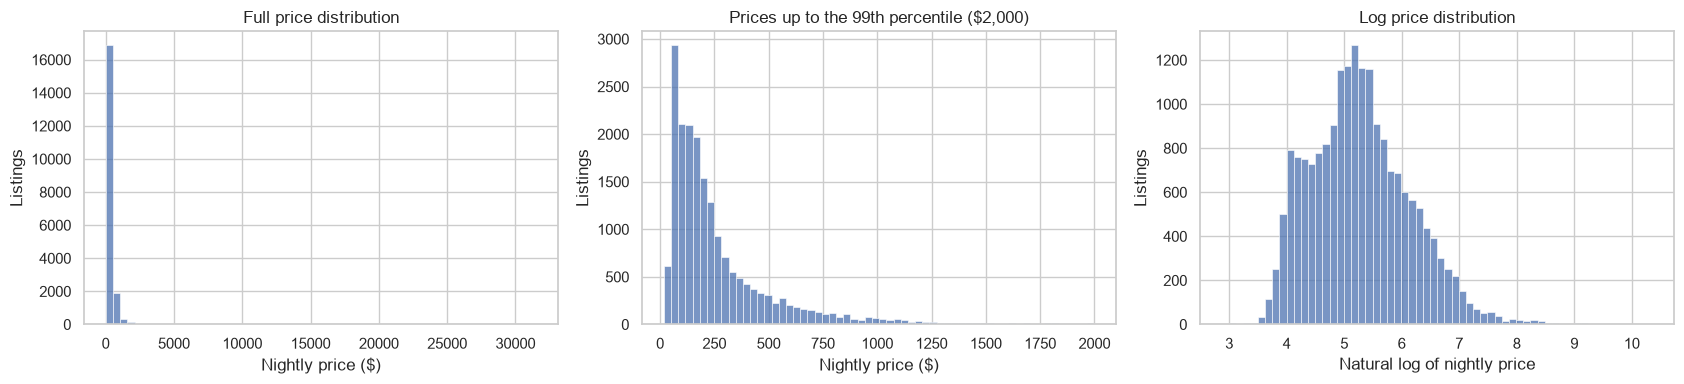

In [19]:
prices = priced_listings["price"]
p99 = prices.quantile(0.99)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

sns.histplot(prices, bins=60, ax=axes[0])
axes[0].set(
    title="Full price distribution",
    xlabel="Nightly price ($)",
    ylabel="Listings",
)

# Filter only for this visualization.
sns.histplot(prices.loc[prices <= p99], bins=60, ax=axes[1])
axes[1].set(
    title=f"Prices up to the 99th percentile (${p99:,.0f})",
    xlabel="Nightly price ($)",
    ylabel="Listings",
)

sns.histplot(np.log(prices), bins=60, ax=axes[2])
axes[2].set(
    title="Log price distribution",
    xlabel="Natural log of nightly price",
    ylabel="Listings",
)

plt.tight_layout()
plt.show()

## Highest-Priced Listings

In [20]:
inspection_columns = [
    "id",
    "name",
    "neighbourhood_group_cleansed",
    "neighbourhood_cleansed",
    "property_type",
    "room_type",
    "accommodates",
    "bedrooms",
    "bathrooms_text",
    "minimum_nights",
    "price",
    "price_quote_checkin_date",
    "price_quote_checkout_date",
    "price_quote_price_per_night",
]

display(
    priced_listings
    .nlargest(15, "price")
    [inspection_columns]
)

,id,name,neighbourhood_group_cleansed,neighbourhood_cleansed,property_type,room_type,accommodates,bedrooms,bathrooms_text,minimum_nights,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_price_per_night
4684,1685032623471298360,"260 West Broadway, Unit 1/2C",Manhattan,Tribeca,Entire rental unit,Entire home/apt,14,7.0,7.5 baths,30.0,31537.82,2026-09-15,2026-10-15,31537.82
9946,1111666023012679487,Opulent Midtown Retreat with White-Gloved Service,Manhattan,Upper East Side,Room in hotel,Hotel room,5,2.0,NaN,1.0,16630.0,2026-09-14,2026-09-15,16630.00
10299,1111666150326773564,"Presidential Suite Park View King Bed, The Pierre",Manhattan,Upper East Side,Room in hotel,Hotel room,5,2.0,2 private baths,1.0,16630.0,2026-09-14,2026-09-15,16630.00
9747,990529,Sunny Luxury Bedroom Guest Bathroom,Manhattan,Murray Hill,Private room in rental unit,Private room,2,1.0,1 bath,30.0,12279.07,2026-09-21,2026-10-21,12279.07
2455,1623431,Enormous Chrysler-View Bedroom/Bath,Manhattan,Midtown,Private room in rental unit,Private room,2,1.0,1 bath,30.0,12217.6,2026-09-21,2026-10-21,12217.60
325,830682282357157632,North Gallery Café,Manhattan,Midtown,Tower,Entire home/apt,16,NaN,2 baths,30.0,12045.03,2026-09-15,2026-10-15,12045.03
15926,830656153550799267,"Eighth House, State of the Art NYC Venue",Manhattan,Midtown,Tower,Entire home/apt,16,NaN,2 baths,30.0,12045.03,2026-09-15,2026-10-15,12045.03
23992,49920227,WELCOME HOME 15 MINUTES TO MANHATTAN BOOK TODAY,Bronx,Longwood,Private room in home,Private room,1,1.0,1 shared bath,30.0,11028.87,2026-09-14,2026-10-14,11028.87
1952,1658149306935018386,King + Twin Suite In The Heart of Manhattan,Manhattan,Gramercy,Room in hotel,Private room,6,2.0,1 private bath,1.0,10988.0,2027-03-09,2027-03-10,10988.00
10345,1111666496980873964,Chic Historic Hotel Steps from 5th Avenue Shops,Manhattan,Upper East Side,Room in hotel,Hotel room,3,1.0,1 private bath,1.0,10461.0,2026-09-14,2026-09-15,10461.00


## Extreme Price Checks

In [21]:
top_prices = priced_listings.nlargest(15, "price")

display(
    top_prices[
        [
            "id",
            "room_type",
            "accommodates",
            "minimum_nights",
            "price",
            "price_quote_price_per_night",
            "price_quote_total_price",
        ]
    ].round(2)
)

,id,room_type,accommodates,minimum_nights,price,price_quote_price_per_night,price_quote_total_price
4684,1685032623471298360,Entire home/apt,14,30.0,31537.82,31537.82,946134.53
9946,1111666023012679487,Hotel room,5,1.0,16630.0,16630.00,16630.00
10299,1111666150326773564,Hotel room,5,1.0,16630.0,16630.00,16630.00
9747,990529,Private room,2,30.0,12279.07,12279.07,368372.00
2455,1623431,Private room,2,30.0,12217.6,12217.60,366528.00
325,830682282357157632,Entire home/apt,16,30.0,12045.03,12045.03,361351.00
15926,830656153550799267,Entire home/apt,16,30.0,12045.03,12045.03,361351.00
23992,49920227,Private room,1,30.0,11028.87,11028.87,330866.00
1952,1658149306935018386,Private room,6,1.0,10988.0,10988.00,10988.00
10345,1111666496980873964,Hotel room,3,1.0,10461.0,10461.00,10461.00


In [22]:
quote_check = priced_listings[
    [
        "id",
        "price",
        "price_quote_checkin_date",
        "price_quote_checkout_date",
    ]
].copy()

quote_check["checkin"] = pd.to_datetime(
    quote_check["price_quote_checkin_date"], errors="coerce"
)

quote_check["checkout"] = pd.to_datetime(
    quote_check["price_quote_checkout_date"], errors="coerce"
)

quote_check["quoted_nights"] = (
    quote_check["checkout"] - quote_check["checkin"]
).dt.days

display(
    quote_check["quoted_nights"]
    .describe()
    .to_frame()
    .round(2)
)

display(
    quote_check.loc[
        top_prices.index,
        ["id", "price", "quoted_nights"],
    ]
)

,quoted_nights
count,19406.00
mean,23.88
std,19.08
min,1.00
25%,4.00
50%,30.00
75%,30.00
max,365.00


,id,price,quoted_nights
4684,1685032623471298360,31537.82,30
9946,1111666023012679487,16630.0,1
10299,1111666150326773564,16630.0,1
9747,990529,12279.07,30
2455,1623431,12217.6,30
325,830682282357157632,12045.03,30
15926,830656153550799267,12045.03,30
23992,49920227,11028.87,30
1952,1658149306935018386,10988.0,1
10345,1111666496980873964,10461.0,1


## Price by Room Type and Borough

In [23]:
for column in ["room_type", "neighbourhood_group_cleansed"]:
    summary = (
        priced_listings.groupby(column)
        .agg(
            listings=("price", "size"),
            median_price=("price", "median"),
            mean_price=("price", "mean"),
            price_25th=("price", lambda x: x.quantile(0.25)),
            price_75th=("price", lambda x: x.quantile(0.75)),
        )
        .sort_values("median_price", ascending=False)
        .round(2)
    )

    print(f"\nPrice by {column}:")
    display(summary)


Price by room_type:


,listings,median_price,mean_price,price_25th,price_75th
room_type,,,,,
Hotel room,429,649.94,1030.51,450.0,1022.84
Entire home/apt,10111,218.0,338.35,150.12,361.65
Private room,8711,115.15,244.23,68.81,257.0
Shared room,155,91.12,183.55,44.22,218.6



Price by neighbourhood_group_cleansed:


,listings,median_price,mean_price,price_25th,price_75th
neighbourhood_group_cleansed,,,,,
Manhattan,8757,265.44,443.77,157.96,521.19
Brooklyn,6358,156.34,218.82,88.67,250.93
Queens,3240,126.0,180.23,74.42,194.8
Bronx,765,107.68,153.76,68.89,166.15
Staten Island,286,105.56,140.21,74.86,168.06


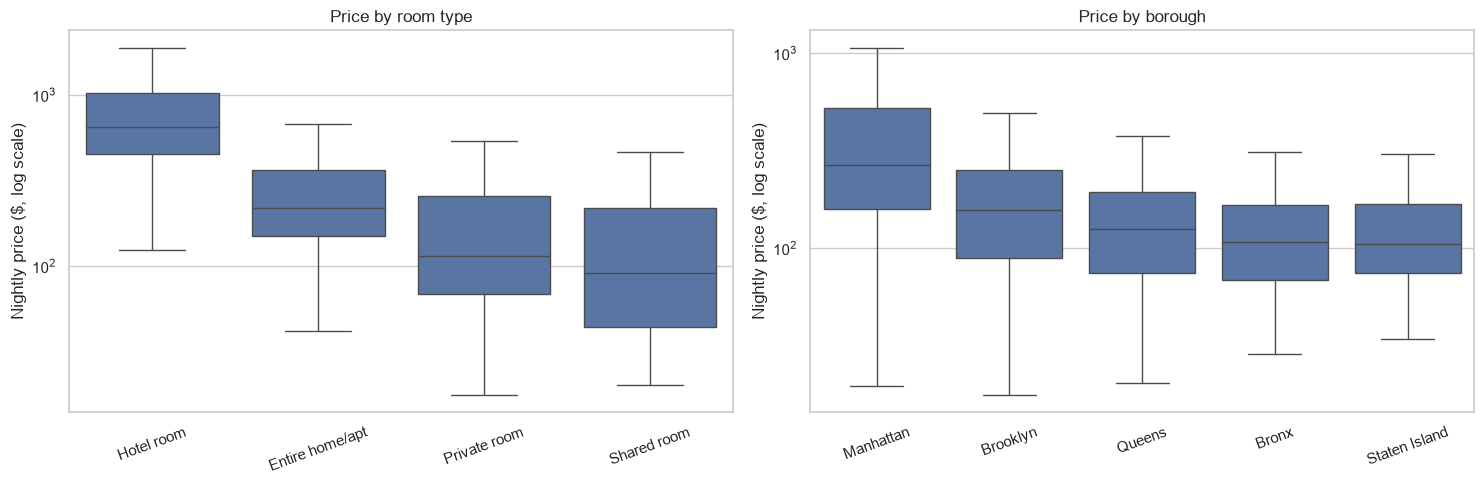

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, column, title in [
    (axes[0], "room_type", "Price by room type"),
    (axes[1], "neighbourhood_group_cleansed", "Price by borough"),
]:
    order = (
        priced_listings.groupby(column)["price"]
        .median()
        .sort_values(ascending=False)
        .index
    )

    sns.boxplot(
        data=priced_listings,
        x=column,
        y="price",
        order=order,
        showfliers=False,
        ax=ax,
    )

    ax.set_yscale("log")
    ax.set(
        title=title,
        xlabel="",
        ylabel="Nightly price ($, log scale)",
    )
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## Price by Borough Within Room Type

In [25]:
borough_order = [
    "Manhattan",
    "Brooklyn",
    "Queens",
    "Bronx",
    "Staten Island",
]

room_order = [
    "Entire home/apt",
    "Private room",
    "Shared room",
    "Hotel room",
]

median_prices = (
    priced_listings.pivot_table(
        index="neighbourhood_group_cleansed",
        columns="room_type",
        values="price",
        aggfunc="median",
    )
    .reindex(index=borough_order, columns=room_order)
)

listing_counts = (
    pd.crosstab(
        priced_listings["neighbourhood_group_cleansed"],
        priced_listings["room_type"],
    )
    .reindex(index=borough_order, columns=room_order, fill_value=0)
)

print("Median nightly price ($):")
display(median_prices.round(2))

print("Listing counts:")
display(listing_counts)

Median nightly price ($):


room_type,Entire home/apt,Private room,Shared room,Hotel room
neighbourhood_group_cleansed,,,,
Manhattan,254.54,256.0,56.96,755.71
Brooklyn,195.53,101.01,107.2,315.0
Queens,161.0,90.45,109.78,459.0
Bronx,135.73,80.8,<NA>,210.0
Staten Island,118.27,91.76,110.0,<NA>


Listing counts:


room_type,Entire home/apt,Private room,Shared room,Hotel room
neighbourhood_group_cleansed,,,,
Manhattan,5506,2897,42,312
Brooklyn,3009,3234,75,40
Queens,1187,1945,35,73
Bronx,281,480,0,4
Staten Island,128,155,3,0


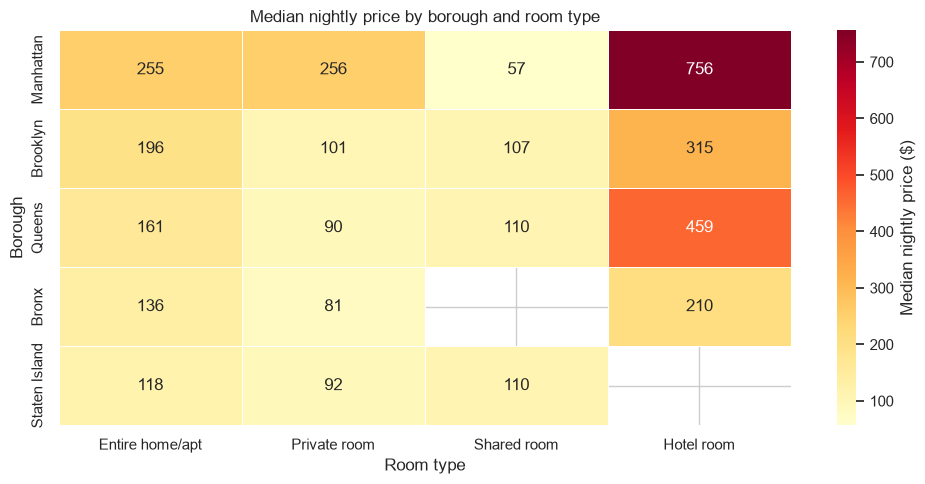

In [27]:
heatmap_values = median_prices.to_numpy(
    dtype=float,
    na_value=np.nan,
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(
    heatmap_values,
    mask=np.isnan(heatmap_values),
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5,
    xticklabels=median_prices.columns,
    yticklabels=median_prices.index,
    cbar_kws={"label": "Median nightly price ($)"},
    ax=ax,
)

ax.set(
    title="Median nightly price by borough and room type",
    xlabel="Room type",
    ylabel="Borough",
)

plt.tight_layout()
plt.show()